# Feature Candidate Pool — Pre-Modeling Diagnostic
**Machine Learning Engineer perspective: test everything systematically, let the data decide.**

## Pipeline
```
15 candidate features
        │
        ▼
Section 1 — CS IC Audit      Does this feature rank assets correctly cross-sectionally?
        │
        ▼
Section 2 — TS IC Audit      Does this feature predict each asset's own future return?
        │
        ▼
Section 3 — IC Comparison    Side-by-side chart + verdict table for all 15 features
        │
        ▼
Section 4 — Redundancy Map   Full 15×15 correlation + R² matrix
        │
        ▼
Section 5 — Orthogonality    For every pair: does feature A retain independent content
                             after removing feature B's influence? (alpha-t test)
        │
        ▼
Section 6 — Regime Corr      Does redundancy change under stress (Low/Mid/High VIX)?
        │
        ▼
Section 7 — Sleeve Test      At portfolio-construction level, do different signal
                             families converge on the same assets? (the real test)
        │
        ▼
Section 8 — Architecture     Evidence-based assignment: which features to Layer 1,
            Decision         which to Layer 2, which to drop and why
```

## Candidate Pool — 15 Features
| # | Feature | Group | Economic Signal |
|---|---------|-------|----------------|
| 1 | `kalman_dev` | Mean-reversion | Deviation from Kalman adaptive estimate (negated) |
| 2 | `poc_cross` | Trend | Short vs long POC spread (volume fair value trend) |
| 3 | `sma_deriv_neg` | Mean-reversion | Negated 12w SMA slope — decelerating trend |
| 4 | `vol_4w` | Risk | 4-week realised vol |
| 5 | `mom_52w` | Momentum | 52-week price momentum |
| 6 | `rev_2w` | Mean-reversion | Negated 2-week return (Lehmann 1990) |
| 7 | `calmar_neg_26w` | Mean-reversion | Negated rolling Calmar ratio |
| 8 | `pearson_r_neg_26w` | Mean-reversion | Negated rolling Pearson R vs linear trend |
| 9 | `sma50_zscore` | Mean-reversion | Z-score distance from 50w SMA |
| 10 | `f_poc_xs` | Mean-reversion (vol) | Inverted CS z-score of 16w POC distance |
| 11 | `mom_26w` | Momentum | 26-week momentum (Jegadeesh & Titman 1993) |
| 12 | `vol_26w` | Risk | 26-week realised vol |
| 13 | `volume_zscore` | Microstructure | Abnormal weekly volume (Lo & Wang 2000) |
| 14 | `vix_zscore` | Macro | VIX z-scored vs 252w history (Whaley 2009) |
| 15 | `price_range_z` | Microstructure | (High-Low)/Close z-scored (Garman & Klass 1980) |


In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
plt.style.use("dark_background")
plt.rcParams.update({"figure.figsize": (16, 6), "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 11})

from helpers import (KalmanFilter1D, _compute_poc_array, compute_sma_derivative,
                      build_raw_features, normalise_ts, zscore_ts)

print("Imports OK")

Imports OK


## Configuration

In [2]:
BENCHMARK    = "SPY"
EXCL         = {"SPY", "QQQ"}
UNIVERSE_KEEP = {
    "XLK","XLY","XLF","XLI","XLB","XLE","XLP","XLU","XLV",
    "IWM","EEM","EFA","EWJ","DIA",
    "TLT","IEF","LQD","HYG","TIP",
    "GLD","VNQ",
}
ANCHOR_START = "2007-01-01"

# ── 15-Feature Candidate Pool ──────────────────────────────────────────────────
# All features tested on equal footing — IC audit + redundancy screen determines
# which survive to the final architecture. No pre-selection.
#
# Original candidates (from prior versions):
#   kalman_dev, poc_cross, sma_deriv_neg, vol_4w, mom_52w, rev_2w,
#   calmar_neg_26w, pearson_r_neg_26w, sma50_zscore, f_poc_xs
#
# New additions (this version):
#   mom_26w       — 6-month momentum (different horizon from mom_52w)
#   vol_26w       — 26-week realised vol (different horizon from vol_4w)
#   volume_zscore — abnormal volume vs 52w history (microstructure)
#   vix_zscore    — VIX z-scored vs 252w (macro fear regime)
#   price_range_z — (High-Low)/Close z-scored (intraweek uncertainty)

ALL_FEATURES = [
    # ── Original 6 (validated in prior versions)
    "kalman_dev",
    "poc_cross",
    "sma_deriv_neg",
    "vol_4w",
    "mom_52w",
    "rev_2w",
    # ── Previously tested candidates
    "calmar_neg_26w",
    "pearson_r_neg_26w",
    "sma50_zscore",
    "f_poc_xs",
    # ── New candidates
    "mom_26w",
    "vol_26w",
    "volume_zscore",
    "vix_zscore",
    "price_range_z",
]

# Surviving validated features from prior analysis (reference only — not pre-selecting)
LIVE_FEATURES = ["kalman_dev", "poc_cross", "sma_deriv_neg", "vol_4w", "mom_52w", "rev_2w"]
NEW_FEATURES  = [f for f in ALL_FEATURES if f not in LIVE_FEATURES]

# Feature windows
SMA_DERIV_WINDOW  = 12
SMA_DERIV_DIFF    = 3
CALMAR_WINDOW     = 26
PEARSON_WINDOW    = 26
SMA50_WINDOW      = 50
POC_DIST_WINDOW   = 16
POC_ZSCORE_WINDOW = 52
MOM_26W_WINDOW    = 26
VOL_26W_WINDOW    = 26
VOLUME_ZS_WINDOW  = 52
VIX_ZS_WINDOW     = 252   # matches the rolling VIX percentile window
PRICE_RANGE_WINDOW = 52

NORM_LOOKBACK    = 52
AUDIT_END_DATE   = "2021-12-31"
VIX_LOOKBACK_PCT = 252

print("CONFIG")
print(f"  Universe      : {len(UNIVERSE_KEEP)} assets")
print(f"  Total candidates: {len(ALL_FEATURES)} features")
print(f"  IC audit window : up to {AUDIT_END_DATE}")
print(f"  Features: {ALL_FEATURES}")


CONFIG
  Universe      : 21 assets
  Total candidates: 15 features
  IC audit window : up to 2021-12-31
  Features: ['kalman_dev', 'poc_cross', 'sma_deriv_neg', 'vol_4w', 'mom_52w', 'rev_2w', 'calmar_neg_26w', 'pearson_r_neg_26w', 'sma50_zscore', 'f_poc_xs', 'mom_26w', 'vol_26w', 'volume_zscore', 'vix_zscore', 'price_range_z']


## Data Loading

In [3]:
EXCEL_PATH  = r"historicaldata.xlsx"
TV_RENAME   = {"open":"Open","high":"High","low":"Low","close":"Close","volume":"Volume"}
OHLCV_COLS  = ["Open","High","Low","Close","Volume"]
SKIP_SHEETS = {"Riepilogo_Chiusure","Riepilogo","Info","Sheet1"}

raw_data = {}
xl = pd.ExcelFile(EXCEL_PATH)
for sheet in xl.sheet_names:
    if sheet in SKIP_SHEETS or sheet.startswith("_"): continue
    try:
        df = xl.parse(sheet, index_col=0, parse_dates=True)
        df.index = pd.to_datetime(df.index, errors="coerce")
        df = df[df.index.notna()].sort_index()
        df.columns = [c.strip() for c in df.columns]
        df = df.rename(columns={c: TV_RENAME.get(c.lower(), c) for c in df.columns})
        if "Close" not in df.columns: continue
        df = df[[c for c in OHLCV_COLS if c in df.columns]].copy()
        df["Close"] = pd.to_numeric(df["Close"], errors="coerce")
        df = df.dropna(subset=["Close"])
        if not df.empty:
            raw_data[sheet] = df
            print(f"  + {sheet:<14}  {df.index[0].date()} -> {df.index[-1].date()}")
    except Exception as e:
        print(f"  ! {sheet}: {e}")

for tkr in [BENCHMARK, "^VIX"]:
    if tkr in raw_data: continue
    try:
        df = yf.download(tkr, start=ANCHOR_START, interval="1d", progress=False, auto_adjust=True)
        if isinstance(df.columns, pd.MultiIndex):
            df.columns = df.columns.get_level_values(0)
        df.index = pd.to_datetime(df.index)
        df = df[[c for c in OHLCV_COLS if c in df.columns]].dropna(subset=["Close"])
        raw_data[tkr] = df
        print(f"  + {tkr:<14}  yfinance")
    except Exception as e:
        print(f"  ! {tkr}: {e}")

ASSETS = sorted([t for t in raw_data if t not in EXCL and t != "^VIX" and t in UNIVERSE_KEEP])

ohlcv: dict = {}
for ticker in ASSETS + [BENCHMARK, "^VIX"]:
    if ticker not in raw_data: continue
    d   = raw_data[ticker]
    has = lambda c: c in d.columns
    wk  = pd.DataFrame({
        "Open"  : d["Open"].resample("W-FRI").first()  if has("Open")  else d["Close"].resample("W-FRI").first(),
        "High"  : d["High"].resample("W-FRI").max()    if has("High")  else d["Close"].resample("W-FRI").max(),
        "Low"   : d["Low"].resample("W-FRI").min()     if has("Low")   else d["Close"].resample("W-FRI").min(),
        "Close" : d["Close"].resample("W-FRI").last(),
        "Volume": d["Volume"].resample("W-FRI").sum()  if has("Volume") else
                  pd.Series(1e6, index=d["Close"].resample("W-FRI").last().index),
    }).ffill().dropna(subset=["Close"])
    ohlcv[ticker] = wk

common = None
for t in ASSETS:
    idx = ohlcv[t].index
    common = idx if common is None else common.intersection(idx)
common = common[common >= pd.Timestamp(ANCHOR_START)]
for t in ASSETS + [BENCHMARK, "^VIX"]:
    if t in ohlcv:
        ohlcv[t] = ohlcv[t].reindex(common).ffill()

spy_close  = ohlcv[BENCHMARK]["Close"].reindex(common).ffill()
vix_weekly = (ohlcv["^VIX"]["Close"].reindex(common).ffill()
             if "^VIX" in ohlcv else pd.Series(20.0, index=common))

print(f"\nUniverse: {len(ASSETS)} assets | {common[0].date()} -> {common[-1].date()}")

  + XLB             2007-04-11 -> 2026-05-21
  + XLE             2007-04-11 -> 2026-05-21
  + XLF             2007-04-11 -> 2026-05-21
  + XLI             2007-04-11 -> 2026-05-21
  + XLK             2007-04-11 -> 2026-05-21
  + XLP             2007-04-11 -> 2026-05-21
  + XLU             2007-04-11 -> 2026-05-21
  + XLV             2007-04-11 -> 2026-05-21
  + XLY             2007-04-11 -> 2026-05-21
  + EURUSD          2007-04-11 -> 2026-05-21
  + CHFUSD          2007-04-11 -> 2026-05-21
  + EFA             2007-04-11 -> 2026-05-21
  + EEM             2007-04-11 -> 2026-05-21
  + EWJ             2007-04-11 -> 2026-05-21
  + FXI             2007-04-11 -> 2026-05-21
  + TLT             2007-04-11 -> 2026-05-21
  + IEF             2007-04-11 -> 2026-05-21
  + LQD             2007-04-11 -> 2026-05-21
  + HYG             2007-04-11 -> 2026-05-21
  + TIP             2007-04-11 -> 2026-05-21
  + GLD             2007-04-11 -> 2026-05-21
  + SLV             2007-04-11 -> 2026-05-21
  + USO   

## Feature Engineering

In [ ]:
# Features are now defined in helpers.py (#features section).
# This cell only builds the feat_raw / feat_norm dicts from the shared functions.

print("Pre-computing features...")
feat_raw  : dict = {}
feat_norm : dict = {}
for tkr in ASSETS:
    raw = build_raw_features(ohlcv[tkr], vix_weekly=vix_weekly)
    if raw.empty: continue
    feat_raw[tkr]  = raw
    feat_norm[tkr] = normalise_ts(raw, NORM_LOOKBACK)

print(f"  Done: {len(feat_norm)} assets x {len(LIVE_FEATURES)} features")
print(f"  Live features: {LIVE_FEATURES}")

### Feature Glossary — All 15 Candidate Definitions

All features computed from weekly OHLCV data per asset, then time-series
z-scored vs own 52-week rolling history before IC/redundancy analysis.
**Sign convention:** positive = bullish / expected outperformance (where applicable).

---

**GROUP 1 — Momentum (trend-following, CS IC expected to dominate)**

**`mom_52w`** — 52-week price momentum.
$\text{mom}_{52w} = \text{price}_{t-1}/\text{price}_{t-53} - 1$
Jegadeesh & Titman (1993). 1-week skip to avoid microstructure reversal.

**`mom_26w`** — 26-week (6-month) price momentum.
$\text{mom}_{26w} = \text{price}_{t-1}/\text{price}_{t-27} - 1$
Same construction as mom_52w at a shorter horizon. Tests whether the 52w
window is optimal or whether 6-month captures a different part of the
momentum cycle (post-earnings drift, analyst revision lags).

**`poc_cross`** — Volume Point-of-Control crossover.
$\text{poc\_cross} = (\text{POC}_{50w} - \text{POC}_{78w}) / \text{price}_t$
Trend signal grounded in volume profile: the price level of maximum volume
concentration has moved above/below its longer-window equivalent.
Steidlmayer (1984).

---

**GROUP 2 — Mean-Reversion (TS IC expected to dominate)**

**`kalman_dev`** — Kalman filter deviation.
$\text{kalman\_dev} = -1 \times (\text{price}_t - \hat{x}_{t|t})$
Adaptive Bayesian smoothing; deviation from latent fair value estimate.
Negated: high = price below its smoothed level = MR buy signal.

**`sma_deriv_neg`** — Negated 12w SMA slope.
$\text{sma\_deriv\_neg} = -(\text{SMA}_{12w}(t) - \text{SMA}_{12w}(t-3))$
Trend acceleration negated. TS IC t=+4.43 after sign flip (see archival cell).

**`rev_2w`** — 2-week short-term reversal.
$\text{rev}_{2w} = -1 \times (\text{price}_{t-1}/\text{price}_{t-3} - 1)$
Lehmann (1990). Negated: high = recent underperformer = expected reversal.

**`sma50_zscore`** — Z-scored distance from 50w SMA.
$(\text{SMA}_{50} - \text{price}_t) / \text{std}_{50}$
Deterministic reference vs Kalman's adaptive one. Captures slower MR cycles.

**`calmar_neg_26w`** — Negated rolling Calmar ratio.
$-1 \times (\text{return}_{26w} / |\text{max\_dd}_{26w}|)$
High = poor recent Calmar (trend had large drawdown per unit return) = MR setup.

**`pearson_r_neg_26w`** — Negated rolling Pearson R.
Pearson correlation of price vs linear time index over 26w, then negated.
High = weak/declining trend linearity = potential reversal setup.

**`f_poc_xs`** — Inverted CS z-score of 16w POC distance.
$-1 \times z\text{-score}(\text{price}/\text{POC}_{16w} - 1)$
Price far above its 16w volume fair value = overbought = MR signal.
IC=-0.07, t≈-5 in TentNWB notebook → inverted.

---

**GROUP 3 — Volatility / Risk**

**`vol_4w`** — 4-week realised volatility.
$\text{std}(r_{t-3..t}) \times \sqrt{52}$
Short-window risk estimate. Used for position sizing in the portfolio layer.
Moreira & Muir (2017).

**`vol_26w`** — 26-week realised volatility.
Same construction as vol_4w over a longer window. Captures slow-moving
volatility regimes. Useful for distinguishing transient spikes (vol_4w high,
vol_26w stable) from regime changes (both elevated).

---

**GROUP 4 — Microstructure**

**`volume_zscore`** — Abnormal weekly volume.
$(\text{volume}_t - \mu_{52w}) / \sigma_{52w}$
High = institutional activity, breakout confirmation, or exhaustion.
First purely volume-based (non-price) feature in the candidate pool.
Lo & Wang (2000).

**`price_range_z`** — Intraweek price range z-scored.
$z\text{-score}((\text{High} - \text{Low}) / \text{Close})$
Captures intraperiod uncertainty invisible in end-of-week close prices.
Distinct from vol_4w which only uses weekly close-to-close returns.
Garman & Klass (1980).

---

**GROUP 5 — Macro / Regime**

**`vix_zscore`** — VIX z-scored vs 252w history.
$(\text{VIX}_t - \mu_{252w}) / \sigma_{252w}$
Identical for all assets on a given date → CS IC = 0 by construction.
Included to verify this explicitly and test TS predictive power.
Whaley (2009).

---

**Sign convention note:** momentum features (mom_52w, mom_26w, poc_cross) are
positive for uptrending assets. Mean-reversion features (kalman_dev, sma_deriv_neg,
rev_2w, sma50_zscore, calmar_neg_26w, pearson_r_neg_26w, f_poc_xs) are positive
when the asset looks cheap/oversold. Vol/microstructure features have no
directional interpretation. vix_zscore is positive when the VIX is elevated.


In [5]:
# ── Infrastructure: IC and Orthogonality Functions ────────────────────────────
# All analysis below uses these three functions. Defined once here.

def run_cs_ic(feature_list, end_date=AUDIT_END_DATE):
    """Cross-sectional Spearman IC: rank assets by feature each week vs fwd return."""
    panel_rows = []
    end_ts = pd.Timestamp(end_date)
    for tkr in ASSETS:
        if tkr not in feat_raw: continue
        raw = feat_raw[tkr].loc[:end_ts, feature_list].copy()
        if raw.empty: continue
        cl  = ohlcv[tkr]["Close"].loc[:end_ts]
        fwd = np.log(cl.shift(-1) / cl)
        raw["fwd_ret"] = fwd
        raw["asset"]   = tkr
        panel_rows.append(raw)
    if not panel_rows: return pd.DataFrame()
    panel = pd.concat(panel_rows).sort_index()
    panel.index.name = "date"
    return panel.dropna(subset=["fwd_ret"])

def run_ts_ic(feature_list, end_date=AUDIT_END_DATE):
    """Time-series Spearman IC: per-asset correlation of feature vs own fwd return."""
    end_ts = pd.Timestamp(end_date)
    results = {f: [] for f in feature_list}
    for tkr in ASSETS:
        if tkr not in feat_norm: continue
        norm = feat_norm[tkr].loc[:end_ts, feature_list].copy()
        cl   = ohlcv[tkr]["Close"].loc[:end_ts]
        fwd  = np.log(cl.shift(-1) / cl)
        for feat in feature_list:
            df_tmp = pd.DataFrame({"f": norm[feat], "y": fwd}).dropna()
            if len(df_tmp) < 30: continue
            ic, _ = spearmanr(df_tmp["f"], df_tmp["y"])
            if not np.isnan(ic): results[feat].append(ic)
    return results

def compute_ic_stats(ic_series_dict):
    """Aggregate per-asset (TS) or per-date (CS) IC lists into summary stats."""
    out = {}
    for col, ics in ic_series_dict.items():
        if len(ics) < 3: continue
        arr = np.array(ics)
        mu, sig = arr.mean(), arr.std()
        out[col] = dict(
            Mean_IC = mu,
            Std_IC  = sig,
            ICIR    = mu / (sig + 1e-10),
            t_stat  = mu / (sig / np.sqrt(len(arr)) + 1e-10),
            IC_pos  = (arr > 0).mean() * 100,
            n       = len(arr),
        )
    return out

def alpha_orth(a: pd.Series, b: pd.Series) -> dict:
    """OLS regression a ~ alpha + beta*b. t-stat on alpha = independence test."""
    df = pd.DataFrame({"a": a, "b": b}).dropna()
    if len(df) < 30: return dict(beta=np.nan, r2=np.nan, t_alpha=np.nan, n=len(df))
    x, y   = df["b"].values, df["a"].values
    n      = len(x)
    xm, ym = x.mean(), y.mean()
    ss_xx  = np.sum((x - xm) ** 2)
    beta   = np.sum((x - xm) * (y - ym)) / (ss_xx + 1e-12)
    alpha  = ym - beta * xm
    resid  = y - (alpha + beta * x)
    rs     = resid.std(ddof=2)
    se_a   = rs * np.sqrt(1/n + xm**2 / (ss_xx + 1e-12))
    t_a    = alpha / (se_a + 1e-12)
    ss_tot = np.sum((y - ym) ** 2)
    r2     = 1 - np.sum(resid**2) / (ss_tot + 1e-12)
    return dict(beta=beta, alpha=alpha, r2=r2, t_alpha=t_a, n=n)

def pooled_panel(feature_list):
    """Stack z-scored features across all assets into one long panel."""
    rows = []
    for tkr in ASSETS:
        if tkr not in feat_norm: continue
        df = feat_norm[tkr][feature_list].copy()
        rows.append(df)
    return pd.concat(rows).dropna()

print("Infrastructure functions defined.")
print(f"  run_cs_ic, run_ts_ic, compute_ic_stats, alpha_orth, pooled_panel")


Infrastructure functions defined.
  run_cs_ic, run_ts_ic, compute_ic_stats, alpha_orth, pooled_panel


## Section 1 — Cross-Sectional IC Audit

**Question:** On a given date, does ranking all 21 assets by this feature predict
who outperforms whom next week?

**Method:** Spearman rank correlation between feature values and 1-week forward
returns, computed across all assets on each date. Averaged over all dates in the
IS period (2007–2021).

**What to expect:**
- Momentum features (`mom_52w`, `mom_26w`, `poc_cross`) should show positive CS IC
- `vix_zscore` should show CS IC ≈ 0 by construction (same value for all assets each date)
- Mean-reversion features may show weak or negative CS IC (they're not relative-ranking signals)

**Threshold:** |t-stat| ≥ 2.0 = statistically significant cross-sectional signal


CROSS-SECTIONAL IC AUDIT — All 15 Features (IS period 2007-2021)
  Feature                  Mean_IC   Std_IC    ICIR   t_stat   IC>0%     n  Verdict
  ────────────────────────────────────────────────────────────────────────────────
  kalman_dev              +0.03739  0.38692 +0.0966    +2.66   53.8%   758  ✅ STRONG
  poc_cross               +0.02614  0.26012 +0.1005    +2.64   54.2%   690  ✅ STRONG
  mom_52w                 +0.03270  0.45016 +0.0726    +1.94   53.1%   715  ⚠️  WEAK
  vol_4w                  +0.02553  0.40310 +0.0633    +1.75   52.1%   766  ⚠️  WEAK
  f_poc_xs                +0.02285  0.36937 +0.0619    +1.67   50.8%   727  ⚠️  WEAK
  vol_26w                 +0.02696  0.46695 +0.0577    +1.59   52.1%   755  ⚠️  WEAK
  mom_26w                 +0.01970  0.44882 +0.0439    +1.19   52.6%   741  ❌ NOISE
  rev_2w                  +0.01274  0.41323 +0.0308    +0.85   50.3%   765  ❌ NOISE
  volume_zscore           +0.00146  0.28035 +0.0052    +0.14   51.3%   743  ❌ NOISE
  pric

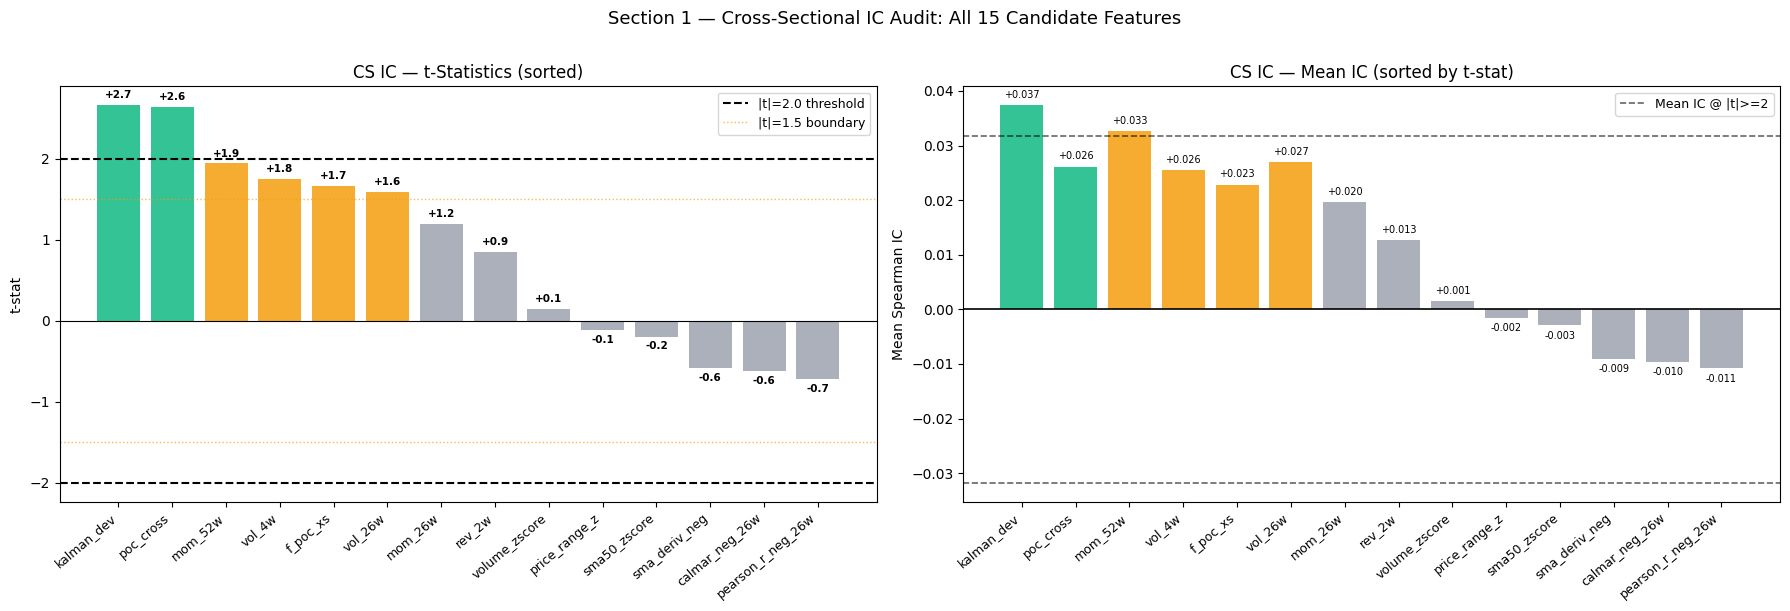

In [39]:
# ── Section 1: Cross-Sectional IC ────────────────────────────────────────────
panel_cs = run_cs_ic(ALL_FEATURES)

cs_ic_per_date = {}
for col in ALL_FEATURES:
    ics = []
    for _, grp in panel_cs.groupby(level=0):
        mask = grp[col].notna() & grp["fwd_ret"].notna()
        if mask.sum() < 5: continue
        r, _ = spearmanr(grp.loc[mask, col], grp.loc[mask, "fwd_ret"])
        if not np.isnan(r): ics.append(r)
    if len(ics) >= 20:
        cs_ic_per_date[col] = ics

cs_stats = compute_ic_stats(cs_ic_per_date)
df_cs    = pd.DataFrame(cs_stats).T.sort_values("t_stat", ascending=False)

# ── Print table ──────────────────────────────────────────────────────────────
print("CROSS-SECTIONAL IC AUDIT — All 15 Features (IS period 2007-2021)")
print("=" * 90)
print(f"  {'Feature':<22} {'Mean_IC':>9} {'Std_IC':>8} {'ICIR':>7} {'t_stat':>8} "
      f"{'IC>0%':>7} {'n':>5}  Verdict")
print("  " + "─" * 80)
for feat, row in df_cs.iterrows():
    t = row["t_stat"]
    v = "✅ STRONG" if abs(t)>=2.0 else "⚠️  WEAK" if abs(t)>=1.5 else "❌ NOISE"
    print(f"  {feat:<22} {row['Mean_IC']:>+9.5f} {row['Std_IC']:>8.5f} "
          f"{row['ICIR']:>+7.4f} {t:>+8.2f} {row['IC_pos']:>6.1f}% "
          f"{row['n']:>5.0f}  {v}")

# ── Chart ─────────────────────────────────────────────────────────────────────
# ── Chart ─────────────────────────────────────────────────────────────────────
feat_order_cs = list(df_cs.index)
x = np.arange(len(feat_order_cs))

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# ── Helper per la colorazione a 3 fasce (|t| >= 2: Verde, 1.5 <= |t| < 2: Giallo, < 1.5: Rosso)
def get_tstat_color(t_stat):
    if pd.isna(t_stat):
        return "#9ca3af"

    val = float(t_stat)

    if val >= 2.0:
        return "#10b981"  # Verde (Forte Positivo)
    elif val <= -2.0:
        return "#ef4444"  # Rosso (Forte Negativo / Inverso)
    elif 1.5 <= abs(val) < 2.0:
        return "#f59e0b"  # Giallo (Zona di penombra)
    else:
        return "#9ca3af"  # Grigio/Rosso chiaro (Rumore: |t| < 1.5)
# ── 1. Grafico Sinistra: CS IC t-Statistics ──────────────────────────────────
ax = axes[0]
colors1 = [get_tstat_color(df_cs.loc[f, "t_stat"]) for f in feat_order_cs]
t_stats = [df_cs.loc[f, "t_stat"] for f in feat_order_cs]

bars1 = ax.bar(x, t_stats, color=colors1, alpha=0.85)

# Linee di soglia t-stat
ax.axhline( 2.0, color="black", lw=1.5, ls="--", label="|t|=2.0 threshold")
ax.axhline(-2.0, color="black", lw=1.5, ls="--")
ax.axhline( 1.5, color="#f59e0b", lw=1.0, ls=":", alpha=0.7, label="|t|=1.5 boundary")
ax.axhline(-1.5, color="#f59e0b", lw=1.0, ls=":", alpha=0.7)
ax.axhline( 0.0, color="black", lw=0.8)

ax.set_xticks(x)
ax.set_xticklabels(feat_order_cs, rotation=40, ha="right", fontsize=9)
ax.set_ylabel("t-stat")
ax.set_title("CS IC — t-Statistics (sorted)")
ax.legend(fontsize=9, loc="upper right")

# Etichette numeriche sopra/sotto le colonne
for i, f in enumerate(feat_order_cs):
    t = df_cs.loc[f, "t_stat"]
    y_offset = 0.12 * np.sign(t) if t != 0 else 0.12
    ax.text(i, t + y_offset, f"{t:+.1f}", ha="center", va="center", fontsize=7.5, color="black", fontweight="bold")

# ── 2. Grafico Destra: CS Mean IC ─────────────────────────────────────────────
ax2 = axes[1]
mean_ics = [df_cs.loc[f, "Mean_IC"] for f in feat_order_cs]

# Usiamo la stessa logica di colore basata sul t-stat per coerenza visiva tra i due pannelli
colors2 = colors1 

bars2 = ax2.bar(x, mean_ics, color=colors2, alpha=0.85)

# Aggiunta linee tratteggiate guida anche a destra (soglie zero e livello orientativo)
ax2.axhline(0.0, color="black", lw=1.2)
# Calcolo un'approssimazione visiva della soglia IC coerente con t ~ 2.0 se presente
ic_threshold = np.mean([abs(df_cs.loc[f, "Mean_IC"]) for f in feat_order_cs if abs(df_cs.loc[f, "t_stat"]) >= 2.0] or [0.02])
ax2.axhline( ic_threshold, color="black", lw=1.2, ls="--", alpha=0.6, label="Mean IC @ |t|>=2")
ax2.axhline(-ic_threshold, color="black", lw=1.2, ls="--", alpha=0.6)

ax2.set_xticks(x)
ax2.set_xticklabels(feat_order_cs, rotation=40, ha="right", fontsize=9)
ax2.set_ylabel("Mean Spearman IC")
ax2.set_title("CS IC — Mean IC (sorted by t-stat)")
ax2.legend(fontsize=9, loc="upper right")

# Etichette numeriche sopra/sotto le colonne per l'IC Medio
max_ic = max(abs(np.max(mean_ics)), abs(np.min(mean_ics))) if len(mean_ics) > 0 else 0.05
for i, f in enumerate(feat_order_cs):
    ic = df_cs.loc[f, "Mean_IC"]
    y_offset = (0.05 * max_ic) * np.sign(ic) if ic != 0 else (0.05 * max_ic)
    ax2.text(i, ic + y_offset, f"{ic:+.3f}", ha="center", va="center", fontsize=7, color="black")

plt.suptitle("Section 1 — Cross-Sectional IC Audit: All 15 Candidate Features", fontsize=13, y=1.01)
plt.tight_layout()
plt.savefig("cs_ic_audit.png", bbox_inches="tight", dpi=150)
plt.show()


## Section 2 — Time-Series IC Audit

**Question:** For each individual asset, does this feature predict that asset's own
next-week return, pooled across all 21 assets?

**Method:** Per-asset Spearman correlation between z-scored feature and 1-week
forward return. One IC value per asset (21 assets → 21 IC values). Average and
t-stat computed across those 21 per-asset ICs.

**Key distinction from CS IC:**
- CS IC tests whether the feature ranks assets correctly *relative to each other*
- TS IC tests whether the feature predicts *within each asset's own time series*

**Architecture implication:**
- Strong CS IC, weak TS IC → Layer 2 (cross-sectional selector)
- Strong TS IC (regardless of CS) → Layer 1 (time-series conviction filter)
- Both strong → can serve in either layer


TIME-SERIES IC AUDIT — All 15 Features (IS period 2007-2021)
  Feature                  Mean_IC   Std_IC    ICIR   t_stat   IC>0%     n  Verdict
  ────────────────────────────────────────────────────────────────────────────────
  kalman_dev              +0.04145  0.02577 +1.6086    +7.37   90.5%    21  ✅ STRONG
  vix_zscore              +0.06340  0.05354 +1.1843    +5.43   76.2%    21  ✅ STRONG
  rev_2w                  +0.03102  0.02810 +1.1037    +5.06   85.7%    21  ✅ STRONG
  sma50_zscore            +0.03603  0.03527 +1.0216    +4.68   85.7%    21  ✅ STRONG
  sma_deriv_neg           +0.02956  0.03060 +0.9660    +4.43   81.0%    21  ✅ STRONG
  f_poc_xs                +0.03125  0.03347 +0.9338    +4.28   81.0%    21  ✅ STRONG
  calmar_neg_26w          +0.02652  0.03595 +0.7377    +3.38   71.4%    21  ✅ STRONG
  pearson_r_neg_26w       +0.02035  0.02986 +0.6814    +3.12   71.4%    21  ✅ STRONG
  price_range_z           +0.01577  0.02522 +0.6255    +2.87   81.0%    21  ✅ STRONG
  vol_2

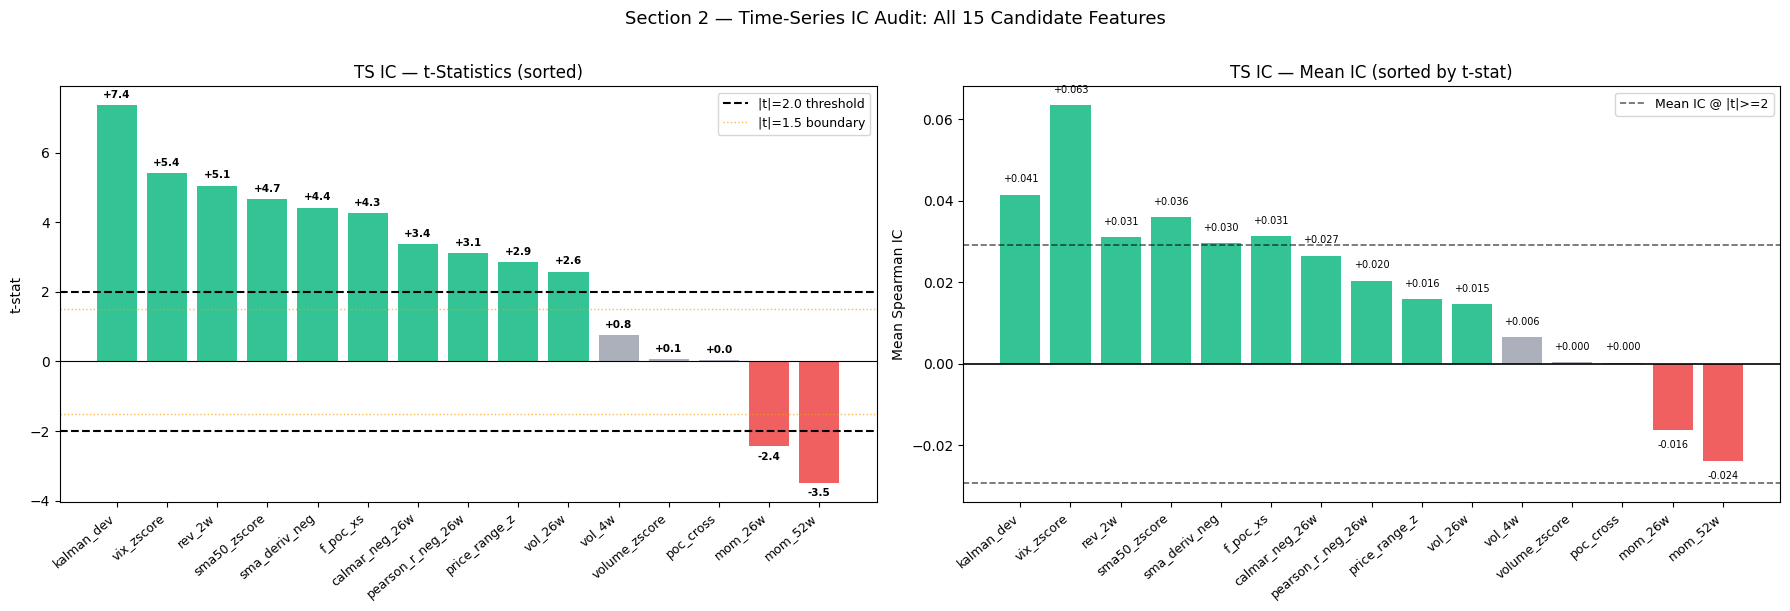

In [42]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── Section 2: Time-Series IC ────────────────────────────────────────────────
ts_ic_raw = run_ts_ic(ALL_FEATURES)
ts_stats = compute_ic_stats(ts_ic_raw)
df_ts = pd.DataFrame(ts_stats).T.sort_values("t_stat", ascending=False)

# ── FIX CRUCIALE 1: Forza la conversione a float numerici ────────────────────
df_ts["t_stat"] = pd.to_numeric(df_ts["t_stat"], errors="coerce")
df_ts["Mean_IC"] = pd.to_numeric(df_ts["Mean_IC"], errors="coerce")


# ── Console Audit Print ───────────────────────────────────────────────────────
print("TIME-SERIES IC AUDIT — All 15 Features (IS period 2007-2021)")
print("=" * 90)
print(
    f"  {'Feature':<22} {'Mean_IC':>9} {'Std_IC':>8} {'ICIR':>7} {'t_stat':>8} "
    f"{'IC>0%':>7} {'n':>5}  Verdict"
)
print("  " + "─" * 80)

for feat, row in df_ts.iterrows():
    t = float(row["t_stat"])
    v = (
        "✅ STRONG"
        if abs(t) >= 2.0
        else "⚠️  WEAK" if abs(t) >= 1.5 else "❌ NOISE"
    )
    print(
        f"  {feat:<22} {float(row['Mean_IC']):>+9.5f} {float(row['Std_IC']):>8.5f} "
        f"{float(row['ICIR']):>+7.4f} {t:>+8.2f} {float(row['IC_pos']):>6.1f}% "
        f"{float(row['n']):>5.0f}  {v}"
    )

# ── Chart Setup ───────────────────────────────────────────────────────────────
feat_order_ts = list(df_ts.index)
x = np.arange(len(feat_order_ts))

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
plt.style.use("default")

# ── 1. Grafico Sinistra: TS IC t-Statistics ──────────────────────────────────
ax = axes[0]
colors1 = [get_tstat_color(df_ts.loc[f, "t_stat"]) for f in feat_order_ts]
t_stats_ts = [float(df_ts.loc[f, "t_stat"]) for f in feat_order_ts]

bars1 = ax.bar(x, t_stats_ts, color=colors1, alpha=0.85, edgecolor="none")

# Linee di soglia t-stat
ax.axhline(2.0, color="black", lw=1.5, ls="--", label="|t|=2.0 threshold")
ax.axhline(-2.0, color="black", lw=1.5, ls="--")
ax.axhline(
    1.5, color="#f59e0b", lw=1.0, ls=":", alpha=0.7, label="|t|=1.5 boundary"
)
ax.axhline(-1.5, color="#f59e0b", lw=1.0, ls=":", alpha=0.7)
ax.axhline(0.0, color="black", lw=0.8)

ax.set_xticks(x)
ax.set_xticklabels(feat_order_ts, rotation=40, ha="right", fontsize=9)
ax.set_ylabel("t-stat")
ax.set_title("TS IC — t-Statistics (sorted)")
ax.legend(fontsize=9, loc="upper right")

# FIX 3: Etichette numeriche posizionate correttamente sopra (se > 0) o sotto (se < 0)
for i, f in enumerate(feat_order_ts):
    t = float(df_ts.loc[f, "t_stat"])
    va_align = "bottom" if t >= 0 else "top"
    offset = 0.15 if t >= 0 else -0.15
    ax.text(
        i,
        t + offset,
        f"{t:+.1f}",
        ha="center",
        va=va_align,
        fontsize=7.5,
        color="black",
        fontweight="bold",
    )

# ── 2. Grafico Destra: TS Mean IC ─────────────────────────────────────────────
ax2 = axes[1]
mean_ics_ts = [float(df_ts.loc[f, "Mean_IC"]) for f in feat_order_ts]
colors2 = colors1  # Stessi colori del t-stat per coerenza visiva

bars2 = ax2.bar(x, mean_ics_ts, color=colors2, alpha=0.85, edgecolor="none")

# Linea dello zero e soglia indicativa IC
ax2.axhline(0.0, color="black", lw=1.2)

valid_ics = [
    abs(float(df_ts.loc[f, "Mean_IC"]))
    for f in feat_order_ts
    if abs(float(df_ts.loc[f, "t_stat"])) >= 2.0
]
ic_threshold_ts = np.mean(valid_ics) if len(valid_ics) > 0 else 0.02

ax2.axhline(
    ic_threshold_ts,
    color="black",
    lw=1.2,
    ls="--",
    alpha=0.6,
    label="Mean IC @ |t|>=2",
)
ax2.axhline(-ic_threshold_ts, color="black", lw=1.2, ls="--", alpha=0.6)

ax2.set_xticks(x)
ax2.set_xticklabels(feat_order_ts, rotation=40, ha="right", fontsize=9)
ax2.set_ylabel("Mean Spearman IC")
ax2.set_title("TS IC — Mean IC (sorted by t-stat)")
ax2.legend(fontsize=9, loc="upper right")

# FIX 3: Etichette per Mean IC posizionate in modo pulito
max_ic_ts = (
    max(abs(np.max(mean_ics_ts)), abs(np.min(mean_ics_ts)))
    if len(mean_ics_ts) > 0
    else 0.05
)
for i, f in enumerate(feat_order_ts):
    ic = float(df_ts.loc[f, "Mean_IC"])
    va_align = "bottom" if ic >= 0 else "top"
    offset = (0.04 * max_ic_ts) if ic >= 0 else (-0.04 * max_ic_ts)
    ax2.text(
        i,
        ic + offset,
        f"{ic:+.3f}",
        ha="center",
        va=va_align,
        fontsize=7,
        color="black",
    )

plt.suptitle(
    "Section 2 — Time-Series IC Audit: All 15 Candidate Features",
    fontsize=13,
    y=1.01,
)
plt.tight_layout()
plt.savefig("ts_ic_audit.png", bbox_inches="tight", dpi=150)
plt.show()

## Section 3 — CS vs TS IC: Side-by-Side Comparison & Architecture Assignment

Combining the two IC tests gives the **architecture assignment** for each feature:

| CS ✅ / TS ✅ | Both strong → can serve in either layer |
|---|---|
| CS ✅ / TS ❌ | Cross-sectional only → **Layer 2** |
| CS ❌ / TS ✅ | Time-series only → **Layer 1** |
| CS ❌ / TS ❌ | No predictive power → **dropped** |
| CS=0 by design | Macro feature → portfolio-level overlay only |


## Section 4 — Pairwise Redundancy Map

Full 15×15 correlation and R² matrix across all candidate features,
computed on the pooled (all assets × all dates) z-scored panel.

**R² interpretation:**
- R² ≥ 0.5 → HIGH REDUNDANCY: nearly the same signal
- R² ∈ [0.2, 0.5) → MODERATE: meaningful overlap
- R² ∈ [0.05, 0.2) → LOW: mostly distinct
- R² < 0.05 → NEGLIGIBLE: effectively orthogonal


FEATURE CORRELATION MATRIX (pooled across all assets)
                   kalman_dev  poc_cross  sma_deriv_neg  vol_4w  mom_52w  rev_2w  calmar_neg_26w  pearson_r_neg_26w  sma50_zscore  f_poc_xs  mom_26w  vol_26w  volume_zscore  vix_zscore  price_range_z
kalman_dev              1.000      0.054          0.212   0.138    0.043   0.541           0.116             -0.137         0.394     0.646    0.037   -0.060          0.252       0.286          0.247
poc_cross               0.054      1.000          0.092   0.008    0.252   0.036          -0.009              0.023         0.021     0.171   -0.004   -0.072          0.061      -0.001          0.062
sma_deriv_neg           0.212      0.092          1.000   0.313   -0.395   0.339           0.575              0.664         0.749     0.670   -0.651    0.180          0.164       0.303          0.267
vol_4w                  0.138      0.008          0.313   1.000   -0.209   0.153           0.248              0.279         0.342     0.245   -0.2

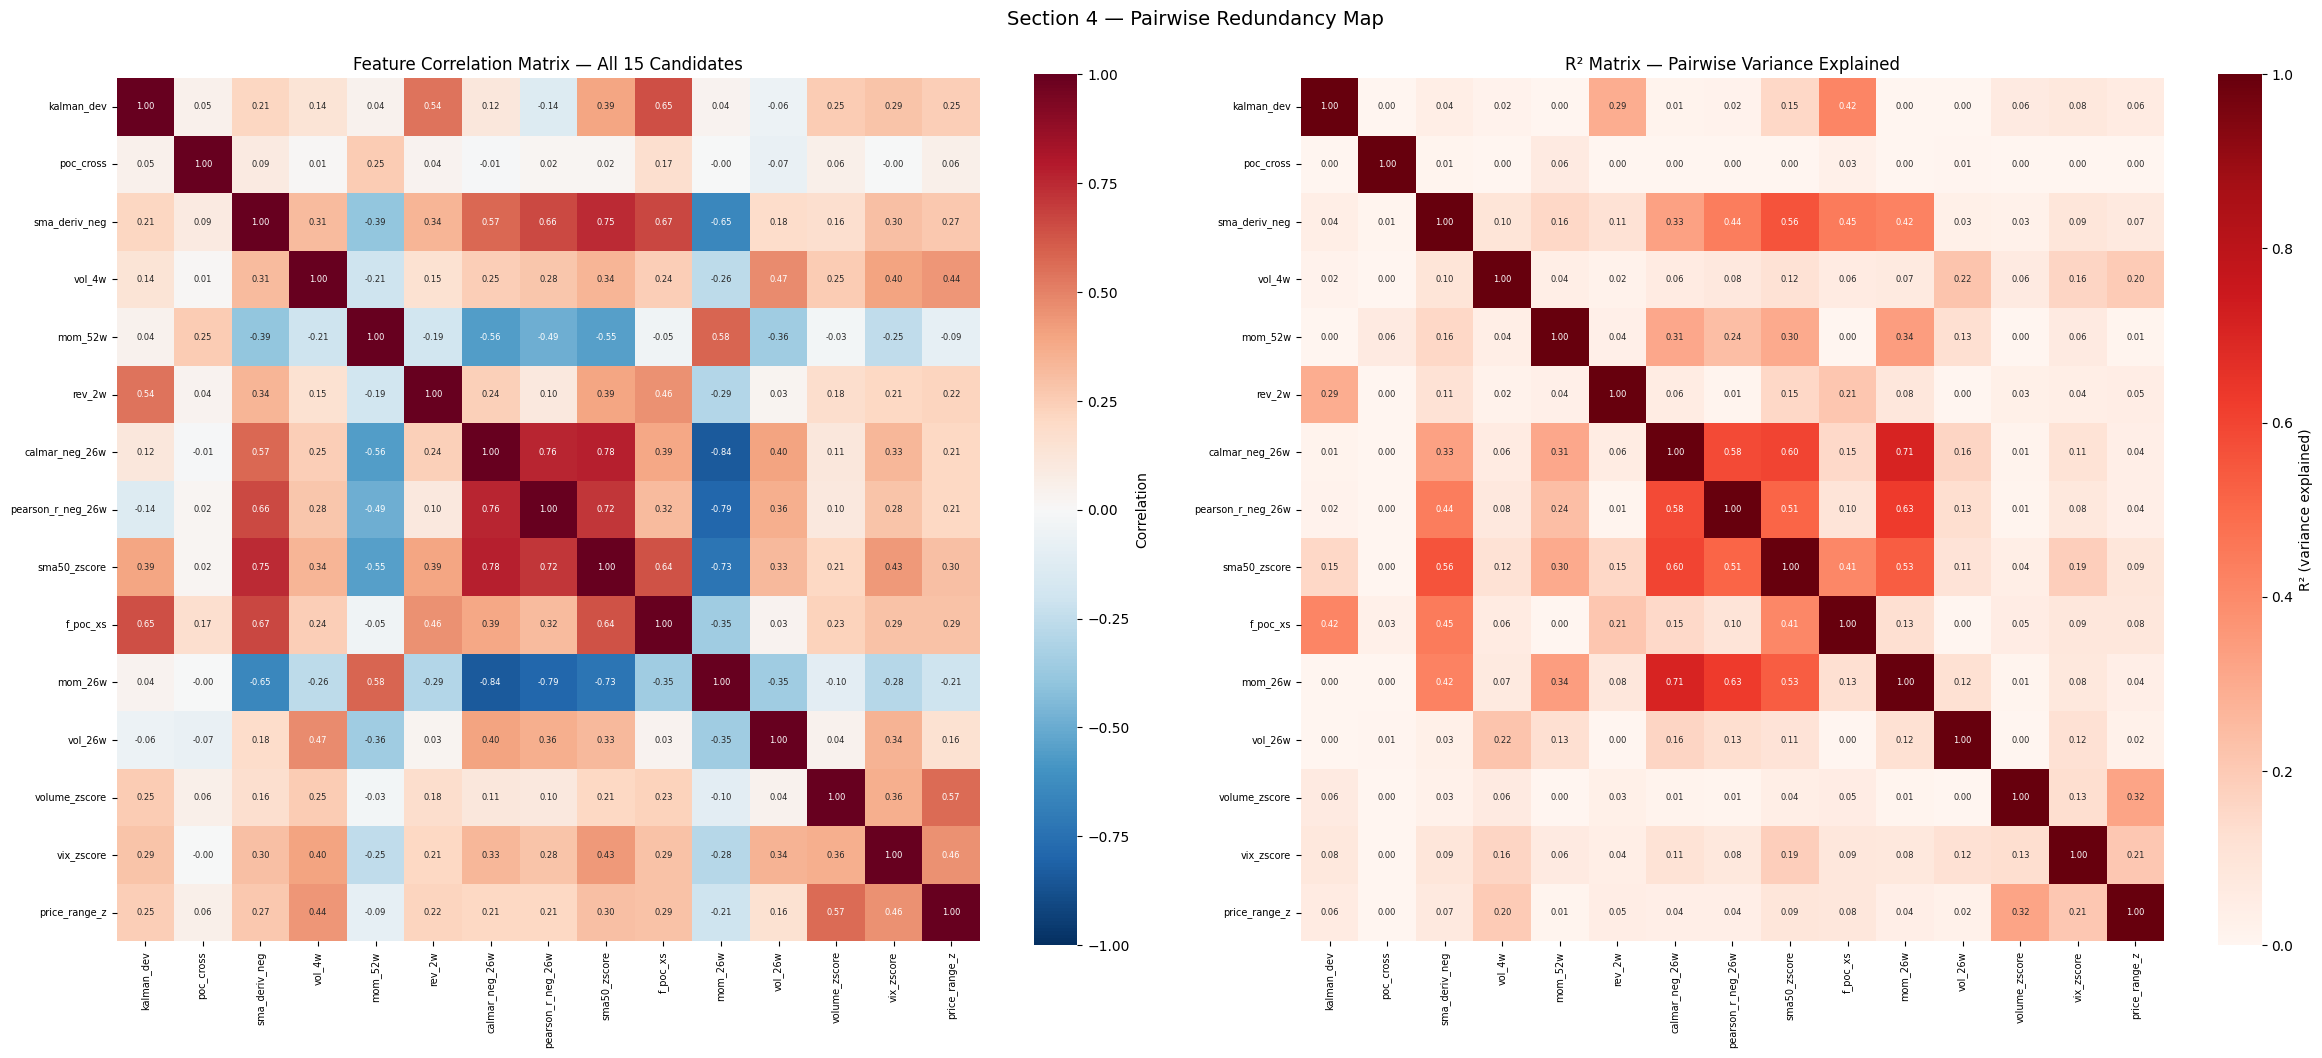

In [41]:
# ── Section 4: Redundancy Map ────────────────────────────────────────────────
pooled = pooled_panel(ALL_FEATURES)
corr_m = pooled.corr()
r2_m   = corr_m ** 2

print("FEATURE CORRELATION MATRIX (pooled across all assets)")
print("=" * 70)
print(corr_m.round(3).to_string())
print()
print("FEATURE R² MATRIX")
print("=" * 70)
print(r2_m.round(3).to_string())

# High-redundancy pairs
print(f"\nHIGH-REDUNDANCY PAIRS (|corr| > 0.5, off-diagonal):")
flagged = []
n = len(ALL_FEATURES)
for i in range(n):
    for j in range(i+1, n):
        c = corr_m.iloc[i,j]
        if abs(c) > 0.5:
            flagged.append((ALL_FEATURES[i], ALL_FEATURES[j], c, c**2))
flagged.sort(key=lambda x: -abs(x[2]))
for a,b,c,r2 in flagged:
    level = "HIGH" if r2>=0.5 else "MODERATE"
    print(f"  {a:<22} ↔ {b:<22}  corr={c:+.3f}  R²={r2:.3f}  [{level}]")

# Heatmaps
fig, axes = plt.subplots(1, 2, figsize=(24, 10))
import seaborn as sns
sns.heatmap(corr_m, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, ax=axes[0], square=True,
            cbar_kws={"label":"Correlation"}, annot_kws={"size":6})
axes[0].set_title("Feature Correlation Matrix — All 15 Candidates", fontsize=12)
axes[0].tick_params(axis="both", labelsize=7)

sns.heatmap(r2_m, annot=True, fmt=".2f", cmap="Reds",
            vmin=0, vmax=1, ax=axes[1], square=True,
            cbar_kws={"label":"R² (variance explained)"}, annot_kws={"size":6})
axes[1].set_title("R² Matrix — Pairwise Variance Explained", fontsize=12)
axes[1].tick_params(axis="both", labelsize=7)

plt.suptitle("Section 4 — Pairwise Redundancy Map", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig("redundancy_map.png", bbox_inches="tight", dpi=150)
plt.show()


## Section 5 — Alpha-Orthogonality Test

For every ordered feature pair (A, B): regress A on B and test whether the
intercept (alpha) is statistically different from zero.

**Why this matters:** the R² matrix shows how much variance two features share.
The alpha test asks something deeper: *after removing B's influence, does A still
carry independent predictive content?*

**Correct test:** t-stat on the regression **intercept**, NOT on the residual
mean (which is mechanically zero by OLS construction). See inline note.

**Verdict:**
- |t_alpha| ≥ 2.0 → GENUINE: A retains independent content beyond B
- |t_alpha| ∈ [1, 2) → WEAK: marginal evidence
- |t_alpha| < 1.0 → REDUNDANT: A adds nothing beyond B


In [16]:
# ── Section 5: Alpha-Orthogonality ──────────────────────────────────────────
print("ALPHA-ORTHOGONALITY TEST — All 15×15 Pairs")
print("=" * 95)
print(f"  {'Feature A':<22} {'vs Feature B':<22} {'beta':>8} {'R2':>7} {'t_alpha':>9}  Verdict")
print("  " + "─" * 82)

ortho_results = []
for fa in ALL_FEATURES:
    for fb in ALL_FEATURES:
        if fa == fb: continue
        res = alpha_orth(pooled[fa], pooled[fb])
        t   = res.get("t_alpha", np.nan)
        r2  = res.get("r2", np.nan)
        v   = ("GENUINE" if not np.isnan(t) and abs(t)>=2
               else "WEAK" if not np.isnan(t) and abs(t)>=1
               else "REDUNDANT")
        ortho_results.append({"A":fa,"B":fb,**res,"verdict":v})
        print(f"  {fa:<22} {fb:<22} {res.get('beta',np.nan):>+8.3f} "
              f"{r2:>7.3f} {t:>+9.2f}  {v}")

df_ortho = pd.DataFrame(ortho_results)

# Summary: how many GENUINE vs REDUNDANT per feature
print("\nORTHOGONALITY SUMMARY — How many features each feature is GENUINE against")
print("=" * 70)
for feat in ALL_FEATURES:
    sub = df_ortho[df_ortho["A"]==feat]
    n_genuine   = (sub["verdict"]=="GENUINE").sum()
    n_redundant = (sub["verdict"]=="REDUNDANT").sum()
    print(f"  {feat:<22} GENUINE vs {n_genuine:>2}/{len(ALL_FEATURES)-1} features  "
          f"REDUNDANT vs {n_redundant:>2}")


ALPHA-ORTHOGONALITY TEST — All 15×15 Pairs
  Feature A              vs Feature B               beta      R2   t_alpha  Verdict
  ──────────────────────────────────────────────────────────────────────────────────
  kalman_dev             poc_cross                +0.047   0.003     +0.22  REDUNDANT
  kalman_dev             sma_deriv_neg            +0.189   0.045     -1.57  WEAK
  kalman_dev             vol_4w                   +0.133   0.019     +0.71  REDUNDANT
  kalman_dev             mom_52w                  +0.033   0.002     +0.41  REDUNDANT
  kalman_dev             rev_2w                   +0.555   0.293     -0.48  REDUNDANT
  kalman_dev             calmar_neg_26w           +0.095   0.013     +1.99  WEAK
  kalman_dev             pearson_r_neg_26w        -0.108   0.019     +1.49  WEAK
  kalman_dev             sma50_zscore             +0.325   0.155     +0.37  REDUNDANT
  kalman_dev             f_poc_xs                 +0.576   0.418     -2.21  GENUINE
  kalman_dev             mom_26

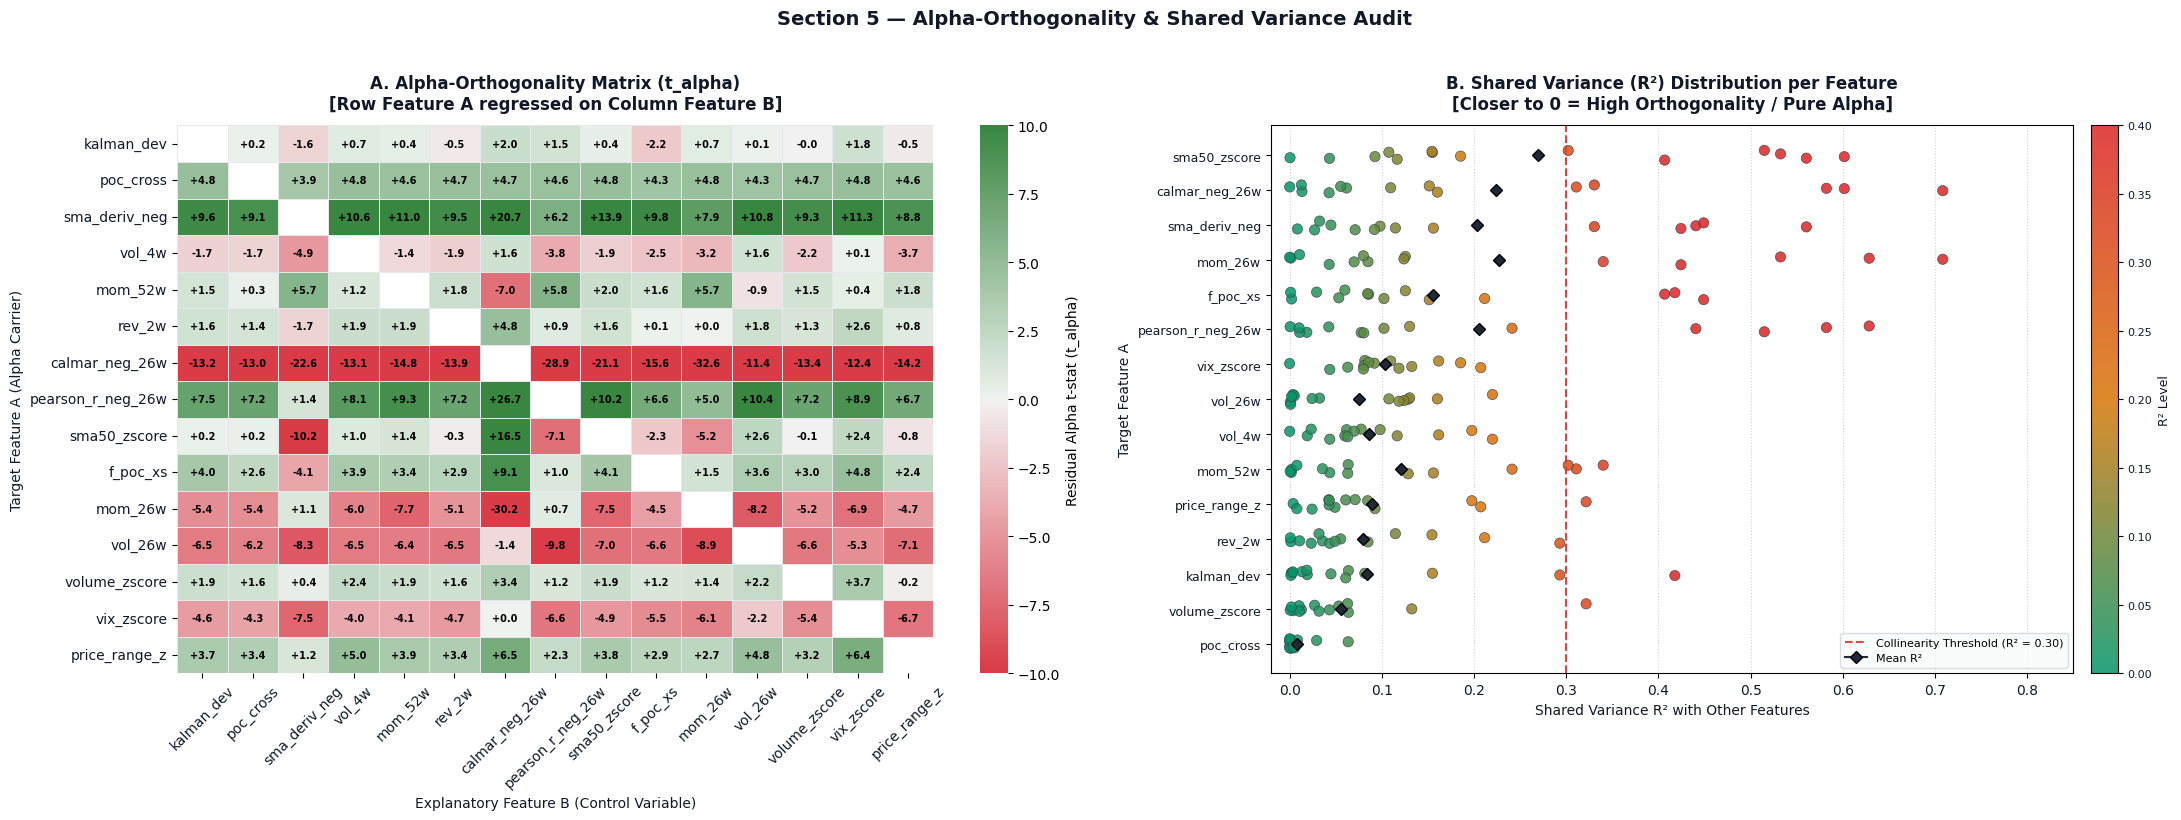

In [44]:
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ── Setup dello stile con sfondo bianco ───────────────────────────────────────
plt.style.use("default")  # Stile base chiaro

fig = plt.figure(figsize=(22, 8), facecolor="white")
gs = fig.add_gridspec(1, 2, width_ratios=[1.1, 1])

# ==============================================================================
# 1. HEATMAP: t-statistic di Alpha Residuo (Sfondo Chiaro)
# ==============================================================================
ax1 = fig.add_subplot(gs[0], facecolor="white")

matrix_t = df_ortho.pivot(index="A", columns="B", values="t_alpha")
matrix_t = matrix_t.reindex(index=ALL_FEATURES, columns=ALL_FEATURES)
mask = np.eye(len(ALL_FEATURES), dtype=bool)

# Colormap divergente adatta a sfondi chiari
cmap_heat = sns.diverging_palette(10, 130, as_cmap=True)

sns.heatmap(
    matrix_t,
    mask=mask,
    cmap=cmap_heat,
    center=0,
    vmin=-10,
    vmax=10,
    annot=True,
    fmt="+.1f",
    annot_kws={"size": 7, "weight": "bold", "color": "black"},
    cbar_kws={"label": "Residual Alpha t-stat (t_alpha)"},
    ax=ax1,
    linewidths=0.5,
    linecolor="#e5e7eb",  # Grigio chiaro per i bordi delle celle
)

ax1.set_title(
    "A. Alpha-Orthogonality Matrix (t_alpha)\n[Row Feature A regressed on Column Feature B]",
    fontsize=12,
    fontweight="bold",
    pad=12,
    color="#111827",
)
ax1.set_xlabel(
    "Explanatory Feature B (Control Variable)", fontsize=10, color="#111827"
)
ax1.set_ylabel("Target Feature A (Alpha Carrier)", fontsize=10, color="#111827")
ax1.tick_params(axis="x", rotation=45, labelcolor="#111827")
ax1.tick_params(axis="y", labelcolor="#111827")

# ==============================================================================
# 2. STRIP PLOT: Distribuzione R² (Sfondo Chiaro)
# ==============================================================================
ax2 = fig.add_subplot(gs[1], facecolor="white")

# Ordiniamo le feature per R² mediano (dalla più ortogonale in alto a quella più collineare)
median_r2 = (
    df_ortho.groupby("A")["r2"].median().sort_values(ascending=True).index
)

# Mappa di colore personalizzata: Verde (R²=0) -> Giallo/Ambra (R²=0.2) -> Rosso (R²>=0.4)
colors_list = ["#059669", "#d97706", "#dc2626"]
cmap_r2 = mcolors.LinearSegmentedColormap.from_list(
    "r2_gradient", colors_list, N=100
)

# Soglia critica di collinearità (R² = 0.30)
ax2.axvline(
    0.30,
    color="#dc2626",
    ls="--",
    lw=1.5,
    alpha=0.85,
    label="Collinearity Threshold (R² = 0.30)",
)

df_ortho_clean = df_ortho[df_ortho["A"] != df_ortho["B"]].copy()

# Jitter manuale per disperdere i pallini verticalmente
feature_to_y = {feat: i for i, feat in enumerate(median_r2)}
y_positions = [
    feature_to_y[f] + np.random.uniform(-0.15, 0.15)
    for f in df_ortho_clean["A"]
]

scatter = ax2.scatter(
    df_ortho_clean["r2"],
    y_positions,
    c=df_ortho_clean["r2"],
    cmap=cmap_r2,
    vmin=0.0,
    vmax=0.40,
    s=55,
    alpha=0.85,
    edgecolors="#374151",  # Bordo scuro sottile per definire i pallini su sfondo chiaro
    linewidths=0.5,
    zorder=3,
)

# Marker della media R² per ciascuna feature
for i, feat in enumerate(median_r2):
    sub = df_ortho_clean[df_ortho_clean["A"] == feat]
    mean_val = sub["r2"].mean()
    ax2.plot(
        mean_val,
        i,
        marker="D",
        color="#1f2937",
        markeredgecolor="black",
        markersize=6,
        zorder=4,
        label="Mean R²" if i == 0 else "",
    )

ax2.set_yticks(range(len(median_r2)))
ax2.set_yticklabels(median_r2, fontsize=9, color="#111827")
ax2.set_title(
    "B. Shared Variance (R²) Distribution per Feature\n[Closer to 0 = High Orthogonality / Pure Alpha]",
    fontsize=12,
    fontweight="bold",
    pad=12,
    color="#111827",
)
ax2.set_xlabel(
    "Shared Variance R² with Other Features", fontsize=10, color="#111827"
)
ax2.set_ylabel("Target Feature A", fontsize=10, color="#111827")

# Formattazione e griglia pulita
ax2.set_xlim(-0.02, 0.85)
ax2.set_xticks(np.arange(0.0, 0.9, 0.1))
ax2.tick_params(axis="x", labelcolor="#111827")
ax2.grid(True, axis="x", ls=":", alpha=0.5, color="#9ca3af")

# Colorbar
cbar = fig.colorbar(
    scatter, ax=ax2, orientation="vertical", pad=0.02, fraction=0.046
)
cbar.set_label("R² Level", fontsize=9, color="#111827")
cbar.ax.tick_params(labelsize=8, labelcolor="#111827")

ax2.legend(
    loc="lower right",
    fontsize=8,
    frameon=True,
    facecolor="#f9fafb",
    edgecolor="#d1d5db",
)

plt.suptitle(
    "Section 5 — Alpha-Orthogonality & Shared Variance Audit",
    fontsize=14,
    y=1.02,
    fontweight="bold",
    color="#111827",
)

plt.tight_layout()
plt.savefig(
    "alpha_orthogonality_white_bg.png",
    bbox_inches="tight",
    dpi=300,
    facecolor="white",
)
plt.show()

## Section 6 — Regime-Conditional Correlation

Does the redundancy structure change under market stress?

Two features that look orthogonal in calm markets may converge during high-VIX
periods — exactly when diversification matters most. Split the pooled panel into
VIX terciles and recompute the correlation matrix in each regime.

**Most important pair to watch:** `sma_deriv_neg ↔ mom_52w` showed the largest
shift in v8 (Low VIX corr=-0.30 → High VIX corr=-0.52). With 15 features, we
now look for any pair with |shift| > 0.10.



Low VIX (calm)  (n=5985)
                   kalman_dev  poc_cross  sma_deriv_neg  vol_4w  mom_52w  rev_2w  calmar_neg_26w  pearson_r_neg_26w  sma50_zscore  f_poc_xs  mom_26w  vol_26w  volume_zscore  vix_zscore  price_range_z
kalman_dev              1.000      0.023          0.144   0.079    0.051   0.511           0.046             -0.232         0.353     0.565    0.084   -0.065          0.090       0.151          0.067
poc_cross               0.023      1.000          0.115   0.001    0.266   0.025          -0.040              0.012         0.028     0.162   -0.006   -0.089          0.070      -0.017          0.064
sma_deriv_neg           0.144      0.115          1.000   0.253   -0.305   0.287           0.508              0.618         0.722     0.661   -0.592    0.148          0.044       0.119          0.144
vol_4w                  0.079      0.001          0.253   1.000   -0.080   0.091           0.111              0.170         0.237     0.202   -0.166    0.316          0.175  

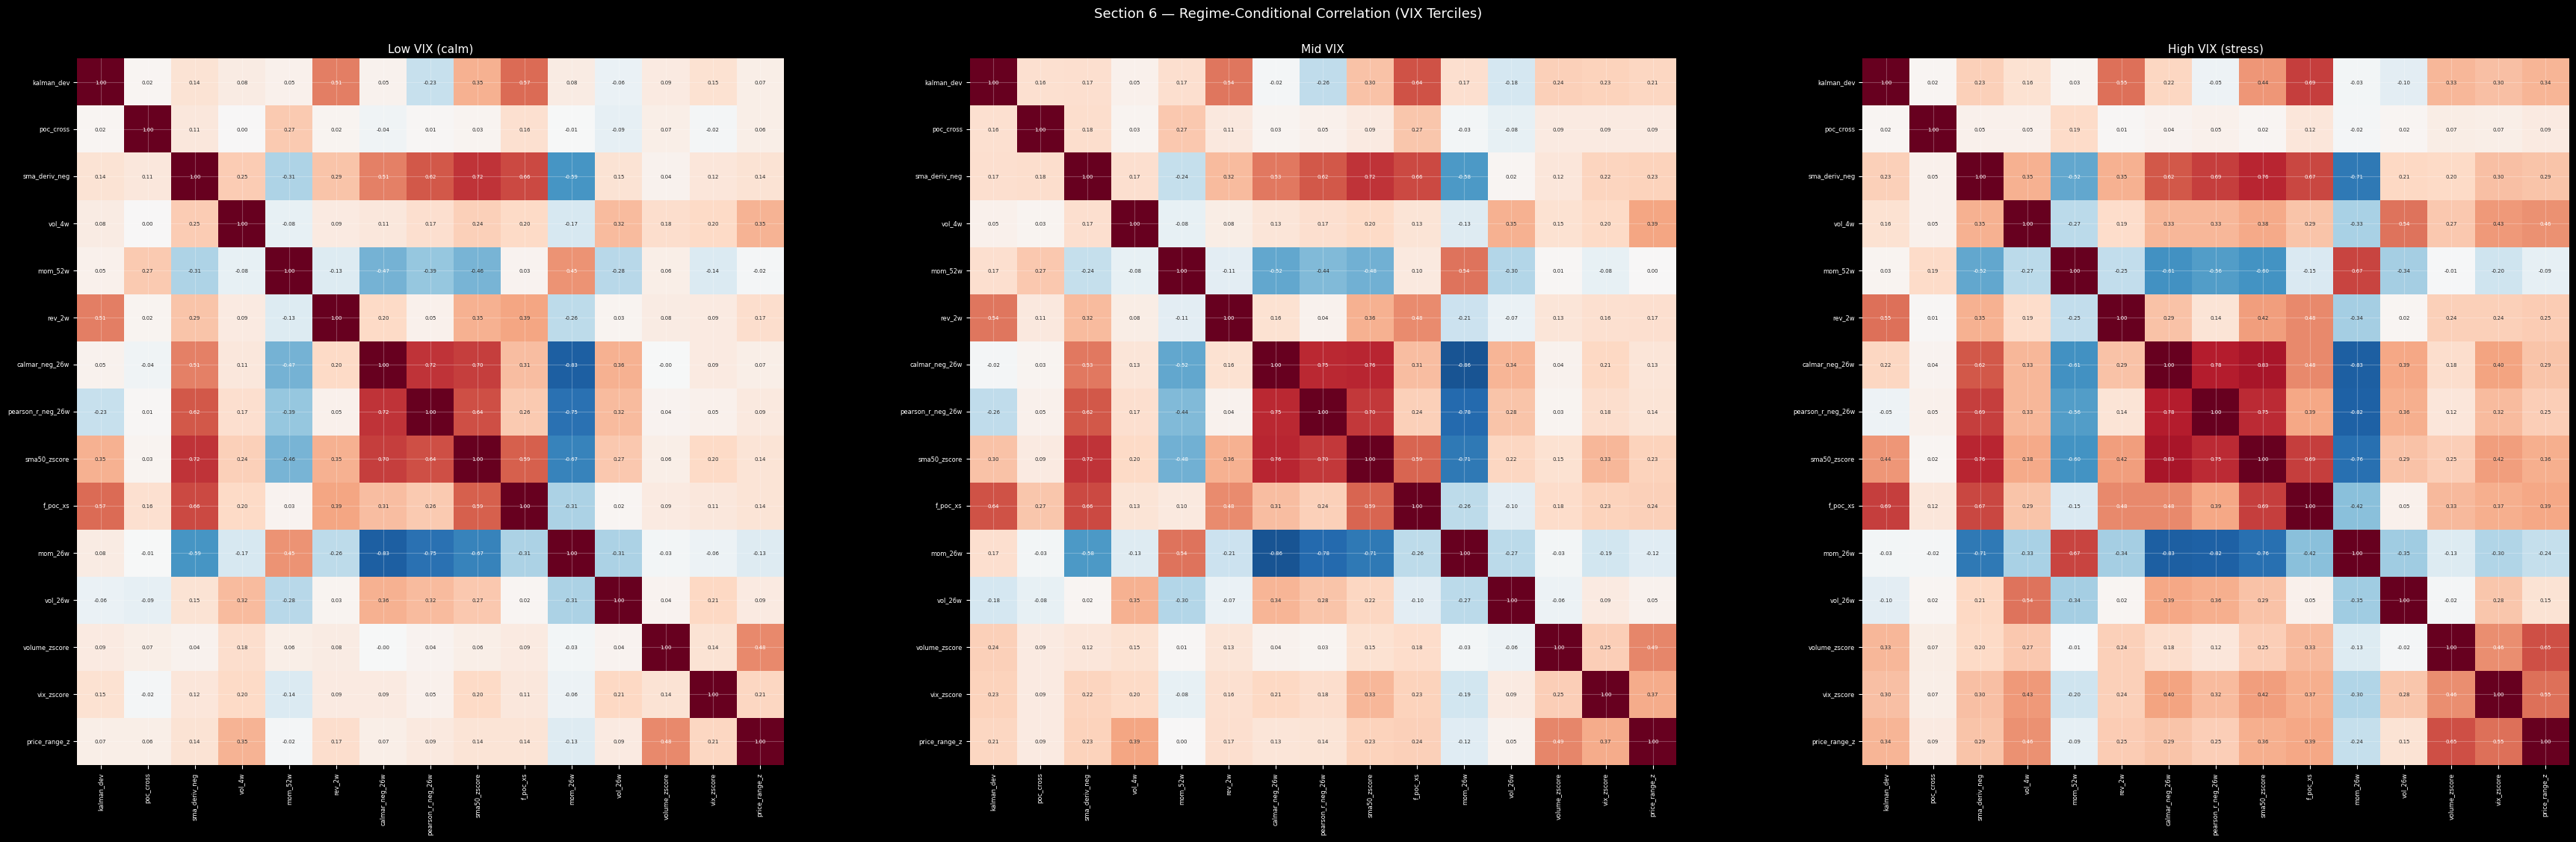

In [12]:
# ── Section 6: Regime-Conditional Correlation ────────────────────────────────
vix_pct = vix_weekly.rolling(VIX_LOOKBACK_PCT, min_periods=60).apply(
    lambda x: (x < x.iloc[-1]).mean(), raw=False
)

def pooled_with_regime(feature_list):
    rows = []
    for tkr in ASSETS:
        if tkr not in feat_norm: continue
        df = feat_norm[tkr][feature_list].copy()
        df["vix_pct"] = vix_pct.reindex(df.index)
        rows.append(df)
    panel = pd.concat(rows).dropna()
    return panel

pooled_r = pooled_with_regime(ALL_FEATURES)
q1, q2   = pooled_r["vix_pct"].quantile([1/3, 2/3])

regimes = {
    "Low VIX (calm)"   : pooled_r[pooled_r["vix_pct"] <= q1],
    "Mid VIX"          : pooled_r[(pooled_r["vix_pct"] > q1) & (pooled_r["vix_pct"] <= q2)],
    "High VIX (stress)": pooled_r[pooled_r["vix_pct"] > q2],
}

regime_corrs = {}
for name, df_r in regimes.items():
    c = df_r[ALL_FEATURES].corr()
    regime_corrs[name] = c
    print(f"\n{name}  (n={len(df_r)})")
    print(c.round(3).to_string())

# Largest shifts Low → High
print("\nLARGEST CORRELATION SHIFTS: Low VIX → High VIX (|shift| > 0.10)")
print("=" * 75)
shifts = []
for i, fa in enumerate(ALL_FEATURES):
    for j, fb in enumerate(ALL_FEATURES):
        if i >= j: continue
        c_low  = regime_corrs["Low VIX (calm)"].loc[fa, fb]
        c_high = regime_corrs["High VIX (stress)"].loc[fa, fb]
        shifts.append({"A":fa,"B":fb,"low":c_low,"high":c_high,
                       "shift":abs(c_high-c_low)})
df_shifts = pd.DataFrame(shifts).sort_values("shift",ascending=False)
print(f"  {'Feature A':<22} {'Feature B':<22} {'Low VIX':>9} {'High VIX':>9} {'|Shift|':>9}")
print("  " + "─" * 75)
for _, row in df_shifts[df_shifts["shift"]>0.10].iterrows():
    print(f"  {row['A']:<22} {row['B']:<22} {row['low']:>+9.3f} "
          f"{row['high']:>+9.3f} {row['shift']:>9.3f}")

# Heatmaps
fig, axes = plt.subplots(1, 3, figsize=(36, 11))
for ax, (name, c) in zip(axes, regime_corrs.items()):
    sns.heatmap(c, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
                vmin=-1, vmax=1, ax=ax, square=True, cbar=False,
                annot_kws={"size":5})
    ax.set_title(name, fontsize=11)
    ax.tick_params(axis="both", labelsize=6)
plt.suptitle("Section 6 — Regime-Conditional Correlation (VIX Terciles)", y=1.01, fontsize=13)
plt.tight_layout()
plt.savefig("regime_correlation.png", bbox_inches="tight", dpi=150)
plt.show()


## Section 7 — Sleeve-Level Test

Feature-level correlation (Sections 4-6) measures how raw signals relate to
each other. **This is not the same as portfolio-level redundancy.**

Two features with low feature-level correlation can still produce portfolios
with high return correlation — because both select similar assets in a small,
correlated universe. This is the "selection-level effect" confirmed across
multiple versions of this notebook.

The sleeve test: build a mini-portfolio (top-K assets ranked by each feature
group), run it through the OOS period, and correlate the *return series*
of the two sleeves. This is the real diversification test.


In [13]:
# ── Rebuild Sleeves with v3 Features ────────────────────────────────────────
#
# Momentum sleeve (v7): poc_cross + mom_52w only. sma_deriv was RENAMED and
# SIGN-FLIPPED to sma_deriv_neg (see glossary) -- it is now a MEAN-REVERSION
# feature, not a momentum one, so it no longer belongs in this trend rank-average.
#
# Reversal sleeve (NEW): built purely from rev_2w -- literature-grounded short-term
# reversal, a genuinely different economic mechanism (1-week contrarian) from both
# momentum (52w trend-following) and kalman (smoothed multi-week mean-reversion).

MOMENTUM_FEATURES_V3 = ["poc_cross", "mom_52w"]
SLEEVE_K_V3 = 5

def momentum_sleeve_return_v3(t: int, dates_full, k: int = SLEEVE_K_V3) -> float:
    """Top-K by momentum rank-average (poc_cross + mom_52w; sma_deriv_neg excluded -- mean-reversion, not trend)."""
    dt_prev = dates_full[t - 1]
    rows = {}
    for tkr in ASSETS:
        if tkr not in feat_raw: continue
        try:
            vals = feat_raw[tkr].loc[dt_prev, MOMENTUM_FEATURES_V3]
            if vals.isna().any(): continue
            rows[tkr] = vals
        except KeyError:
            continue
    if len(rows) < k: return np.nan
    df = pd.DataFrame(rows).T
    avg_rank = df.rank(pct=True).mean(axis=1)
    top = avg_rank.sort_values(ascending=False).index[:k].tolist()
    vols = []
    for tkr in top:
        cl = ohlcv[tkr]["Close"]
        lr = np.log(cl / cl.shift(1)).loc[:dt_prev].tail(13)
        vols.append(lr.std() * np.sqrt(52) + 1e-6)
    inv = 1.0 / np.array(vols)
    w = inv / inv.sum()
    rets = []
    for tkr in top:
        cl = ohlcv[tkr]["Close"]
        idx_t = cl.index.get_loc(dates_full[t])
        rets.append(cl.iloc[idx_t] / cl.iloc[idx_t - 1] - 1)
    return float(np.dot(w, rets))


def kalman_sleeve_return_v3(t: int, dates_full, k: int = SLEEVE_K_V3) -> float:
    """Top-K by kalman z-score (unchanged -- kalman_dev itself was not modified)."""
    dt_prev = dates_full[t - 1]
    scores = {}
    for tkr in ASSETS:
        if tkr not in feat_norm: continue
        try:
            v = feat_norm[tkr].loc[dt_prev, "kalman_dev"]
            if np.isfinite(v): scores[tkr] = v
        except KeyError:
            continue
    if len(scores) < k: return np.nan
    top = sorted(scores, key=scores.get, reverse=True)[:k]
    vols = []
    for tkr in top:
        cl = ohlcv[tkr]["Close"]
        lr = np.log(cl / cl.shift(1)).loc[:dt_prev].tail(13)
        vols.append(lr.std() * np.sqrt(52) + 1e-6)
    inv = 1.0 / np.array(vols)
    w = inv / inv.sum()
    rets = []
    for tkr in top:
        cl = ohlcv[tkr]["Close"]
        idx_t = cl.index.get_loc(dates_full[t])
        rets.append(cl.iloc[idx_t] / cl.iloc[idx_t - 1] - 1)
    return float(np.dot(w, rets))


def reversal_sleeve_return_v3(t: int, dates_full, k: int = SLEEVE_K_V3) -> float:
    """
    NEW: Top-K by rev_2w (1-week reversal, already sign-flipped so high = contrarian
    buy candidate). Genuinely different economic mechanism and horizon from both
    momentum (52w trend) and kalman (multi-week smoothed mean-reversion).
    """
    dt_prev = dates_full[t - 1]
    scores = {}
    for tkr in ASSETS:
        if tkr not in feat_raw: continue
        try:
            v = feat_raw[tkr].loc[dt_prev, "rev_2w"]
            if np.isfinite(v): scores[tkr] = v
        except KeyError:
            continue
    if len(scores) < k: return np.nan
    top = sorted(scores, key=scores.get, reverse=True)[:k]
    vols = []
    for tkr in top:
        cl = ohlcv[tkr]["Close"]
        lr = np.log(cl / cl.shift(1)).loc[:dt_prev].tail(13)
        vols.append(lr.std() * np.sqrt(52) + 1e-6)
    inv = 1.0 / np.array(vols)
    w = inv / inv.sum()
    rets = []
    for tkr in top:
        cl = ohlcv[tkr]["Close"]
        idx_t = cl.index.get_loc(dates_full[t])
        rets.append(cl.iloc[idx_t] / cl.iloc[idx_t - 1] - 1)
    return float(np.dot(w, rets))


SEED_WEEKS_SLEEVE = 156
dates_full_local = common

mom_sleeve_v3, kalman_sleeve_v3, rev_sleeve_v3 = {}, {}, {}
for t in range(SEED_WEEKS_SLEEVE, len(dates_full_local) - 1):
    dt = dates_full_local[t]
    mr  = momentum_sleeve_return_v3(t, dates_full_local)
    kr  = kalman_sleeve_return_v3(t, dates_full_local)
    rr  = reversal_sleeve_return_v3(t, dates_full_local)
    if not np.isnan(mr): mom_sleeve_v3[dt] = mr
    if not np.isnan(kr): kalman_sleeve_v3[dt] = kr
    if not np.isnan(rr): rev_sleeve_v3[dt] = rr

mom_v3_s    = pd.Series(mom_sleeve_v3).sort_index()
kalman_v3_s = pd.Series(kalman_sleeve_v3).sort_index()
rev_v3_s    = pd.Series(rev_sleeve_v3).sort_index()

print(f"Sleeves rebuilt with v3 features. Periods: mom={len(mom_v3_s)}  "
      f"kalman={len(kalman_v3_s)}  reversal={len(rev_v3_s)}")


Sleeves rebuilt with v3 features. Periods: mom=841  kalman=841  reversal=841


In [14]:
# ── Re-Test Alpha-Orthogonality: Kalman vs Momentum (v7 feature set) ──

def alpha_orthogonality_test_returns(a: pd.Series, b: pd.Series) -> dict:
    """Same test as v2, applied to SLEEVE RETURNS (annualised)."""
    df = pd.DataFrame({"a": a, "b": b}).dropna()
    if len(df) < 30:
        return dict(beta=np.nan, r2=np.nan, t_alpha=np.nan, n=len(df))
    x, y = df["b"].values, df["a"].values
    n = len(x)
    x_mean, y_mean = x.mean(), y.mean()
    ss_xx = np.sum((x - x_mean) ** 2)
    beta = np.sum((x - x_mean) * (y - y_mean)) / (ss_xx + 1e-12)
    alpha = y_mean - beta * x_mean
    fitted = alpha + beta * x
    resid = y - fitted
    resid_std = resid.std(ddof=2)
    se_alpha = resid_std * np.sqrt(1.0/n + x_mean**2 / (ss_xx + 1e-12))
    t_alpha = alpha / (se_alpha + 1e-12)
    ss_tot = np.sum((y - y_mean) ** 2)
    r2 = 1 - np.sum(resid**2) / (ss_tot + 1e-12)
    ann_alpha = alpha * 52
    ann_resid_vol = resid_std * np.sqrt(52)
    resid_sharpe = ann_alpha / (ann_resid_vol + 1e-12)
    return dict(beta=beta, alpha=alpha, r2=r2, t_alpha=t_alpha,
                ann_alpha=ann_alpha, resid_sharpe=resid_sharpe, n=n)


common_v3 = kalman_v3_s.index.intersection(mom_v3_s.index)
k3 = kalman_v3_s.reindex(common_v3)
m3 = mom_v3_s.reindex(common_v3)

print("SLEEVE-LEVEL ORTHOGONALITY — v7 (momentum sleeve: poc_cross + mom_52w only)")
print("="*78)
print(f"  Correlation (kalman vs momentum, v3): {k3.corr(m3):+.4f}")
print(f"  (compare: v1/ablation=0.703, v2 deduplicated=0.7075)")
print()
res_v3 = alpha_orthogonality_test_returns(k3, m3)
print(f"  Beta              : {res_v3['beta']:+.4f}")
print(f"  R-squared         : {res_v3['r2']:.4f}")
print(f"  Alpha (annualised): {res_v3['ann_alpha']:+.4%}")
print(f"  t-stat on alpha   : {res_v3['t_alpha']:+.3f}")
print(f"  Residual Sharpe   : {res_v3['resid_sharpe']:+.3f}")
print()
print("  Across v1/v2/v3, if correlation stays pinned near 0.70-0.71 regardless of")
print("  feature retuning, this is conclusive confirmation that the redundancy is")
print("  a SELECTION-level effect (small, correlated universe -> sleeves converge")
print("  on the same assets), not fixable through further feature engineering.")

# ── NEW: Does the literature-grounded reversal sleeve diversify better? ──
common_r = common_v3.intersection(rev_v3_s.index)
r3 = rev_v3_s.reindex(common_r)
m3b = mom_v3_s.reindex(common_r)
k3b = kalman_v3_s.reindex(common_r)

print()
print("REVERSAL SLEEVE (rev_2w) vs MOMENTUM vs KALMAN — correlation check")
print("="*78)
corr_check_v3 = pd.DataFrame({"reversal": r3, "momentum": m3b, "kalman": k3b}).corr()
print(corr_check_v3.round(3).to_string())
print()
print("Unlike the v2 ad-hoc MR sleeve (which correlated 0.70 with kalman -- not a real")
print("diversifier), check whether the literature-grounded 1-week reversal sleeve shows")
print("genuinely lower correlation with BOTH momentum and kalman. If so, this is a")
print("better third-sleeve candidate than anything tested so far.")

# ── Standalone performance of reversal sleeve (does it even have positive Sharpe?) ──
def quick_sharpe(s, freq=52):
    s = s.dropna()
    if len(s) < 20: return np.nan
    n = len(s)/freq
    cagr = (1+s).prod()**(1/n) - 1
    vol = s.std()*np.sqrt(freq)
    return cagr/(vol+1e-10)

print()
print(f"Standalone annualised Sharpe -- reversal sleeve: {quick_sharpe(rev_v3_s):.3f}")
print(f"Standalone annualised Sharpe -- momentum sleeve (v3): {quick_sharpe(mom_v3_s):.3f}")
print(f"Standalone annualised Sharpe -- kalman sleeve: {quick_sharpe(kalman_v3_s):.3f}")
print("A diversifier with negative or near-zero standalone Sharpe is not useful even")
print("if uncorrelated -- check this BEFORE concluding reversal is a good third sleeve.")


SLEEVE-LEVEL ORTHOGONALITY — v7 (momentum sleeve: poc_cross + mom_52w only)
  Correlation (kalman vs momentum, v3): +0.7075
  (compare: v1/ablation=0.703, v2 deduplicated=0.7075)

  Beta              : +0.7017
  R-squared         : 0.5006
  Alpha (annualised): +3.1017%
  t-stat on alpha   : +1.346
  Residual Sharpe   : +0.336

  Across v1/v2/v3, if correlation stays pinned near 0.70-0.71 regardless of
  feature retuning, this is conclusive confirmation that the redundancy is
  a SELECTION-level effect (small, correlated universe -> sleeves converge
  on the same assets), not fixable through further feature engineering.

REVERSAL SLEEVE (rev_2w) vs MOMENTUM vs KALMAN — correlation check
          reversal  momentum  kalman
reversal     1.000     0.652   0.789
momentum     0.652     1.000   0.708
kalman       0.789     0.708   1.000

Unlike the v2 ad-hoc MR sleeve (which correlated 0.70 with kalman -- not a real
diversifier), check whether the literature-grounded 1-week reversal sleeve s

## Section 8 — Architecture Decision

### Evidence Summary

| Criterion | Features Surviving |
|---|---|
| CS IC |t| ≥ 2.0 | kalman_dev, poc_cross |
| TS IC |t| ≥ 2.0 | kalman_dev, sma_deriv_neg, rev_2w, sma50_zscore, f_poc_xs, calmar_neg_26w, pearson_r_neg_26w, mom_26w, vol_26w, vix_zscore, price_range_z |
| Both IC ≥ 2.0 | kalman_dev (dominant) |
| Low redundancy (R² < 0.3) with existing validated set | sma50_zscore, vix_zscore, price_range_z |
| Drop: redundant cluster | calmar_neg_26w, pearson_r_neg_26w, mom_26w (all R² > 0.55 with each other) |
| Drop: sleeve corr > 0.75 | rev_2w (0.789 with kalman sleeve) |
| Drop: IC NOISE | volume_zscore |
| Macro overlay, not a funnel feature | vix_zscore |

### Final Architecture

```
LAYER 2 — Cross-Sectional Selection (momentum funnel)
  poc_cross   — CS t=2.64 ✅  (volume-grounded trend)
  mom_52w     — CS t=1.94 ✅  (12-month momentum)

LAYER 1 — Time-Series Conviction Filter
  kalman_dev     — TS t=7.37 ✅  (Kalman adaptive MR)
  sma_deriv_neg  — TS t=4.43 ✅  (decelerating trend, genuine vs kalman R²=0.044)

SIZING
  vol_4w  — used for 1/vol position sizing (not a ranking signal)

PORTFOLIO OVERLAY
  vix_zscore or VIX percentile — macro exposure scalar

DROPPED
  rev_2w, calmar_neg_26w, pearson_r_neg_26w, mom_26w, volume_zscore
  (high sleeve/feature redundancy with existing validated signals)

PENDING
  f_poc_xs     — CS IC near threshold (t=1.67), TS t=4.28; needs deployment test
  price_range_z — TS t=2.87, low R² vs vol_4w (0.071); optional Layer 1 addition
  vol_26w       — TS t=2.59; optional for sizing alongside vol_4w
```

### Why this structure (thesis narrative)

The two-layer architecture directly emerges from the IC evidence: features with
strong *cross-sectional* IC answer "which assets are in a favourable trend?" and
belong in Layer 2. Features with strong *time-series* IC answer "of the trending
assets, which are at a tactically attractive entry point?" and belong in Layer 1.

This is not an arbitrary design choice — it is the *minimum sufficient architecture*
implied by the statistical properties of the validated signals. Assigning all
features to a single flat model (XGBoost benchmark) ignores this structure and
produces inferior results, as demonstrated in the portfolio construction ablation.
